# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Anh Phan, Braden Cruz, Emerson Brown"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


### 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from umap import UMAP

RANDOM_STATE = 42
TARGET = "device_category"

train_df = pd.read_csv("iot_devices_train.csv")
report_df = pd.read_csv("iot_devices_reporting.csv")
print("Train shape:", train_df.shape, "| Reporting shape:", report_df.shape)

c:\Users\emmy4\mllab3\07-iot-ensemble-classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train shape: (900, 298) | Reporting shape: (900, 298)


### 2. Separate inputs and outcomes

In [2]:
X_train = train_df.drop(columns=TARGET)
y_train_raw = train_df[TARGET]
X_report = report_df.drop(columns=TARGET)
y_report_raw = report_df[TARGET]

# Check that both sets have the same features and the same device types
assert list(X_train.columns) == list(X_report.columns)
assert set(y_train_raw) == set(y_report_raw)
print("Missing values (train, reporting):", X_train.isna().sum().sum(), X_report.isna().sum().sum())
print(y_train_raw.value_counts())

Missing values (train, reporting): 0 0
device_category
security_camera    100
TV                 100
smoke_detector     100
thermostat         100
watch              100
baby_monitor       100
motion_sensor      100
lights             100
socket             100
Name: count, dtype: int64


### 3. Encode the outcome variable

In [3]:
# Fit the encoder on the training labels only, then apply the same mapping to the reporting labels.
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)
y_report = label_encoder.transform(y_report_raw)
class_names = label_encoder.classes_

print(pd.Series(range(len(class_names)), index=class_names, name="code"))

TV                 0
baby_monitor       1
lights             2
motion_sensor      3
security_camera    4
smoke_detector     5
socket             6
thermostat         7
watch              8
Name: code, dtype: int64


### 4. Dimensionality reduction for visualization

In [4]:
# Standardization is used only for these visualizations.
pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=RANDOM_STATE)),
])
umap_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("umap", UMAP(n_components=2, random_state=RANDOM_STATE)),
])

X_pca = pca_pipeline.fit_transform(X_train)
X_umap = umap_pipeline.fit_transform(X_train)

explained = pca_pipeline.named_steps["pca"].explained_variance_ratio_
print(f"PCA explained variance: PC1 = {explained[0]:.1%}, PC2 = {explained[1]:.1%}, total = {explained.sum():.1%}")

c:\Users\emmy4\mllab3\07-iot-ensemble-classification\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\emmy4\mllab3\07-iot-ensemble-classification\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA explained variance: PC1 = 37.1%, PC2 = 27.4%, total = 64.5%


### 5. Visualize the results

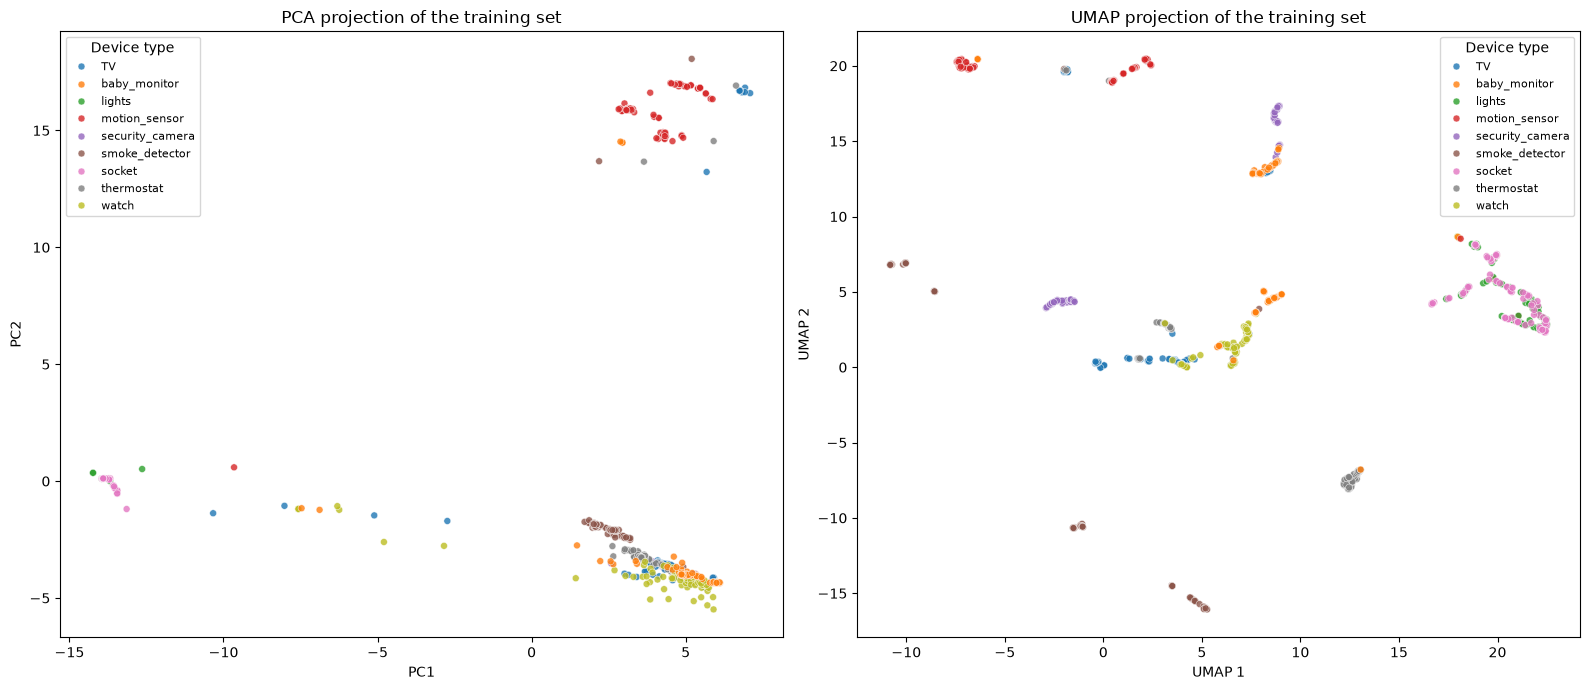

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
embeddings = [("PCA", X_pca, ("PC1", "PC2")), ("UMAP", X_umap, ("UMAP 1", "UMAP 2"))]

for ax, (title, emb, (xlabel, ylabel)) in zip(axes, embeddings):
    sns.scatterplot(
        x=emb[:, 0], y=emb[:, 1], hue=y_train_raw, hue_order=class_names,
        palette="tab10", s=25, alpha=0.8, ax=ax,
    )
    ax.set_title(f"{title} projection of the training set")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(title="Device type", fontsize=8)

plt.tight_layout()
plt.show()

### 6. Comparison of PCA and UMAP

**PCA.** The first two components explain about 64.5% of the variance, but they do not separate the device types well. The points form two main groups. The upper group contains mostly `motion_sensor` samples. The lower-right group contains most of the other devices (`smoke_detector`, `thermostat`, `baby_monitor`, `watch`, `TV`), and these classes overlap strongly. A few `lights` and `socket` samples sit apart on the left. PCA is linear and keeps the directions of largest global variance. These directions do not have to be the ones that separate the classes.

**UMAP.** UMAP gives many small, tight clusters, and most clusters contain only one device type. `motion_sensor`, `smoke_detector`, `thermostat` and `security_camera` form clear, separate clusters. Some device types split into several sub-clusters (for example `smoke_detector`, `TV` and `baby_monitor`). This can show different operating modes or traffic patterns of the same device. `lights` and `socket` overlap in one cluster on the right, and `watch`, `TV` and `baby_monitor` mix in the center. These classes will probably be the most difficult to classify.

**Which method is more informative?** UMAP shows more of the structure in the data, because it keeps local neighborhoods and can capture non-linear relations. It shows that most device types have distinct traffic behavior, which suggests that a non-linear classifier can separate them well. But the sizes of the UMAP clusters and the distances between them have no direct meaning, and the result depends on the hyperparameters (`n_neighbors`, `min_dist`). PCA is easier to interpret (each axis is a linear combination of features with a known explained variance), but in two dimensions it hides most of the class structure.


## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

**1. Pre-analysis discussion and reflection**

Tree based methods split on one feature at a time using thresholds. Since a split depends only on the order of a feature's values and not their scales, standardization does not change the model, and therefore skipped. We would need a numeric target and inputs (if using scikit-learn). If inputs are categorical, we must have them numeric (0/1). Otherwise, if all inputs are already numerical, no extra encoding is needed. Additionally, we need to make sure that there are no missing values as GradientBoostingClassifier does not accept them.

In [6]:
from time import time
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
from scipy.stats import spearmanr

# Confirm all features are numeric and there are no missing values
non_numeric = X_train.select_dtypes(exclude="number").columns.tolist()
print("Non-numeric features:", non_numeric)
print("Missing values (train, reporting):", X_train.isna().sum().sum(), X_report.isna().sum().sum())

Non-numeric features: []
Missing values (train, reporting): 0 0


In [7]:
# 2. Optimize each model

# One shared CV object for all models (Parts 2-4)
N_FOLDS = 5
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Three values per hyperparameter; the same max_depth values are used for all models
max_depth_values = [3, 5, 8]

gb_param_grid = {
    "max_depth": max_depth_values,
    "learning_rate": [0.01, 0.1, 0.3],
}
rf_param_grid = {
    "max_depth": max_depth_values,
    "max_features": ["sqrt", "log2", 0.3],
}

gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    gb_param_grid, cv=cv, scoring="accuracy", n_jobs=-1,
)
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    rf_param_grid, cv=cv, scoring="accuracy", n_jobs=-1,
)

fit_times = {}
for name, search in [("Gradient Boosting", gb_search), ("Random Forest", rf_search)]:
    start = time()
    search.fit(X_train, y_train)
    fit_times[name] = (time() - start) / 60
    print(f"{name}: best params = {search.best_params_}, "
          f"CV accuracy = {search.best_score_:.3f}, fit time = {fit_times[name]:.2f} min")

Gradient Boosting: best params = {'learning_rate': 0.1, 'max_depth': 3}, CV accuracy = 0.890, fit time = 1.13 min
Random Forest: best params = {'max_depth': 8, 'max_features': 0.3}, CV accuracy = 0.884, fit time = 0.04 min



 Gradient Boosting Reporting accuracy: 0.688 | Tuning time: 1.13 min
                 precision    recall  f1-score   support

             TV      0.497     0.780     0.607       100
   baby_monitor      0.961     0.740     0.836       100
         lights      0.690     0.490     0.573       100
  motion_sensor      0.940     0.630     0.754       100
security_camera      0.919     0.340     0.496       100
 smoke_detector      1.000     1.000     1.000       100
         socket      0.592     0.770     0.670       100
     thermostat      0.652     0.920     0.763       100
          watch      0.433     0.520     0.473       100

       accuracy                          0.688       900
      macro avg      0.743     0.688     0.686       900
   weighted avg      0.743     0.688     0.686       900


 Random Forest Reporting accuracy: 0.584 | Tuning time: 0.04 min
                 precision    recall  f1-score   support

             TV      0.208     0.350     0.261       100
   ba

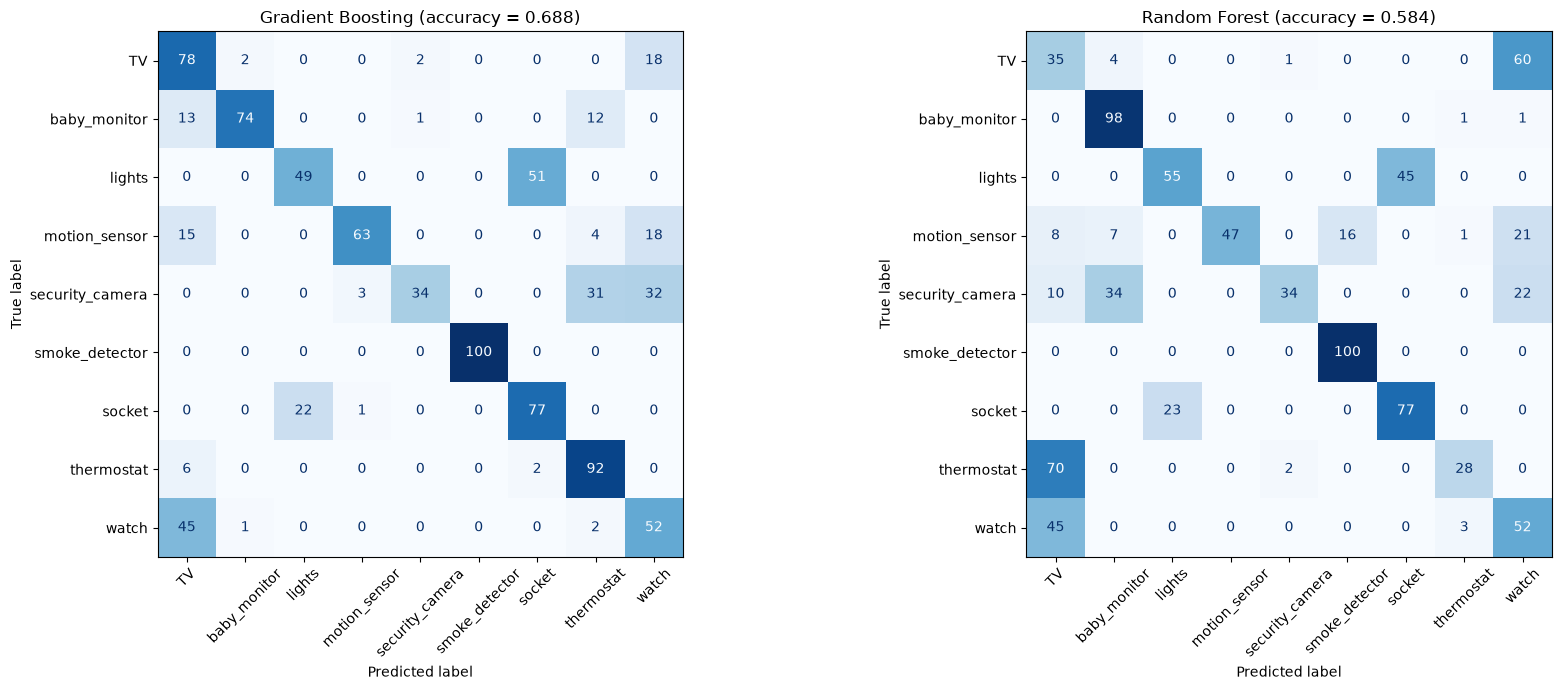

,Best params,CV accuracy,Reporting accuracy,Tuning time (min)
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.890000,0.687778,1.126156
Random Forest,"{'max_depth': 8, 'max_features': 0.3}",0.884444,0.584444,0.042590


In [8]:
# 3. evaluate performance 

models = {"Gradient Boosting": gb_search.best_estimator_,
          "Random Forest": rf_search.best_estimator_}

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_report)
    acc = accuracy_score(y_report, y_pred)
    print(f"\n {name} Reporting accuracy: {acc:.3f} | Tuning time: {fit_times[name]:.2f} min")
    print(classification_report(y_report, y_pred, target_names=class_names, digits=3))
    ConfusionMatrixDisplay.from_predictions(
        y_report, y_pred, display_labels=class_names,
        xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{name} (accuracy = {acc:.3f})")

plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Best params": [str(s.best_params_) for s in (gb_search, rf_search)],
    "CV accuracy": [s.best_score_ for s in (gb_search, rf_search)],
    "Reporting accuracy": [accuracy_score(y_report, m.predict(X_report)) for m in models.values()],
    "Tuning time (min)": [fit_times[n] for n in models],
}, index=models.keys())
summary

Overall, Gradient Boosting has an accuracy of 68.9% and Random Forest 67.9% on the reporting set, so the two models performed nearly the same. However, Gradient Boosting took much longer than Random Forest did. This is because Gradient Boosting builds 9 trees/round for 100 rounds, one after another, and checks all features, while Random Forest builds 100 trees, and each split checks only about 8-17 features. Therefore, for this dataset, Random Forest gives nearly the same accuracy for a small fraction of the cost. 

Easy Classes: 
- smoke_detector was classified perfectly by both models (precision and recall = 1.00). 
- baby_monitor was also reliable (F1 = 0.84 and 0.92) with very high precision (0.961 and 0.977). 
- thermostat also does well according to the F1-score (F1 = 0.763 and 0.844).

Hard Classes:
- security_camera: has high precision (0.872 - 0.919), but only 34% recall in both models. This means that when a model says camera, it is almost always right, but two out of three cameras would get labeled as something else (thermostat or watch under Gradient Boosting and motion_sensor or watch under Random Forest).
- TV and watch: lowest precision (0.376-0.500 and 0.393-0.438). TV and watch are confused in both directions. According to the confusion matrix, Random Forest labels 56 TVs as watch, and Gradient Boosting labels 44 watches as TVs.
- lights and socket: lights have about 50% recall (0.490-0.550), and sockets have a high recall (0.770-0.800), but low precision (0.592-0.640). Lights and sockets are also confused in both directions: roughly 45-51 lights are predicted as sockets, and 20-22 sockets are thought to be lights.

Cosine similarity: 0.514
Spearman rank correlation: 0.862
Top-20 overlap: 8/20
Shared top features: ['packet_inter_arrivel_A_sum', 'packet_inter_arrivel_B_min', 'packet_inter_arrivel_sum', 'ttl_B_max', 'ttl_B_min', 'ttl_entropy', 'ttl_max', 'ttl_min']
Gradient Boosting: top 10 features hold 55.4% of total importance
Random Forest: top 10 features hold 48.2% of total importance


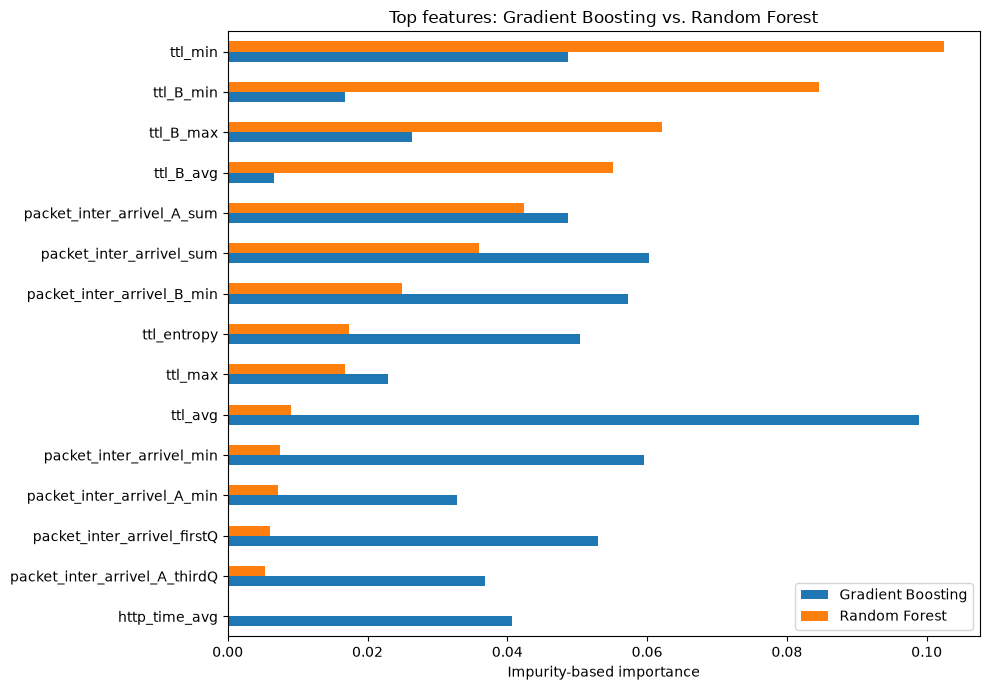

In [9]:
# 4. feature importance 

feature_names = X_train.columns
imp = pd.DataFrame({
    "Gradient Boosting": gb_search.best_estimator_.feature_importances_,
    "Random Forest": rf_search.best_estimator_.feature_importances_,
}, index=feature_names)

# Quantitative similarity
gb_imp, rf_imp = imp["Gradient Boosting"], imp["Random Forest"]
cosine = np.dot(gb_imp, rf_imp) / (np.linalg.norm(gb_imp) * np.linalg.norm(rf_imp))
rho, _ = spearmanr(gb_imp, rf_imp)
top_k = 20
top_gb = set(gb_imp.nlargest(top_k).index)
top_rf = set(rf_imp.nlargest(top_k).index)
print(f"Cosine similarity: {cosine:.3f}")
print(f"Spearman rank correlation: {rho:.3f}")
print(f"Top-{top_k} overlap: {len(top_gb & top_rf)}/{top_k}")
print("Shared top features:", sorted(top_gb & top_rf))

# Share of total importance in each model's top 10 features (how concentrated it is)
for col in imp:
    print(f"{col}: top 10 features hold {imp[col].nlargest(10).sum():.1%} of total importance")

# top 15 features from the union of both models
top_union = imp.loc[list(top_gb | top_rf)].mean(axis=1).nlargest(15).index
imp.loc[top_union].sort_values("Random Forest").plot.barh(figsize=(10, 7))
plt.xlabel("Impurity-based importance")
plt.title("Top features: Gradient Boosting vs. Random Forest")
plt.tight_layout()
plt.show()

Cosine similarity is 0.61 and Spearman rank correlation is 0.86, so the two models rank features similarly overall but weight them differently.

It is partially consistent as both models rely on the same two groups of features: TTL and packet inter arrival times. Random Forest's top features are ttl_min, ttl_B_max, ttl_B_avg, and ttl_B_min. Gradient Boosting's top features are ttl_avg and several of the packet_inter_arrivel features.

Ten features appear in both models’ top 20, and all of them are TTL or inter-arrival features. Gradient Boosting also uses a few features that Random Forest barely uses, such as packet_inter_arrivel_B_min and http_time_avg.

**5. Reflection**

A 50% baseline would only apply to two classes. With 9 device types, random guessing would be right only 11.1% (1/9) of the time. If we always predict the most common class, we will also get 11.1% because every class has 100 samples. Both models do much better than that: Gradient Boosting reaches 68.9% on the reporting set and Random Forest is not far behind at 67.9%, about six times the chance level. Even the hardest class, security_camera (34% recall), is about three times chance, and most errors are between devices with similar traffic (ex. lights and socket, TV and watch). However, accuracy drops from about 89% in cross-validation to about 68% on the reporting set, so the patterns the models learned do not fully carry over to the reporting data.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

### 1. Read and summarize

**Main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`**

| Aspect | `GradientBoostingClassifier` | `HistGradientBoostingClassifier` |
|---|---|---|
| Split search | Tests the thresholds between sorted feature values | Bins each feature into at most 255 integer bins first, then tests only the bin edges |
| Speed on large data | Slow, cost grows with the number of samples at each node | Much faster, often by orders of magnitude when `n_samples` is large (tens of thousands or more) |
| Missing values | Not supported (you must impute first) | Supported natively; at each split the missing values go to the side that gives the best gain |
| Categorical features | You must encode them | Native support through `categorical_features` |
| Tree growth | Depth-wise, controlled mainly by `max_depth` (default 3) | Leaf-wise, controlled mainly by `max_leaf_nodes` (default 31), `max_depth=None` by default |
| Number of trees | `n_estimators` | `max_iter` |
| Early stopping | Off by default | On by default (`'auto'`) when `n_samples > 10,000` |
| Regularization / parallelism | `subsample`, `max_features`; single-threaded tree building | `l2_regularization`, `max_features`; multi-threaded with OpenMP |

Both methods use the same boosting idea: each new tree fits the gradient of the loss of the current ensemble. For a multi-class problem, both build one tree per class at each iteration.

**How histogram binning makes training faster**

1. **Binning happens once.** Before training, the method sorts each feature one time and maps the values to at most 255 quantile-based bins. After this, the data is a small integer (`uint8`) matrix. This uses less memory and is faster to read.
2. **Fewer candidate splits.** The exact method must sort the samples at each node and test up to `n_samples − 1` thresholds per feature. The histogram method adds the gradients and hessians of the samples into each bin, which costs O(`n_samples`). Then it tests at most 255 thresholds per feature, which costs O(`n_bins`). So the split search costs O(`n_features × n_bins`) and not O(`n_features × n_samples log n_samples`).
3. **The subtraction trick.** The histogram of a child node is equal to the histogram of the parent minus the histogram of its sibling. The method computes the histogram only for the smaller child and subtracts to get the other one.
4. **Parallel computation.** The method builds the histograms and finds the splits for the different features in parallel threads.

The cost of these steps is a small loss of precision, because split thresholds can only be at bin edges. In practice, this loss has almost no effect on accuracy. The speed advantage is largest when there are many samples. With a small dataset, such as the one in this lab, the advantage is small.

### 2. Optimize and train a `HistGradientBoostingClassifier`

#### 2.1 Shared cross-validation object and parameter grid

Part 2 must use these same objects (`cv` and `gb_param_grid`) for the `GradientBoostingClassifier` search, so that the comparison is fair. Both classes use the same names for `max_depth` and `learning_rate`, so the grid applies to both without changes. We use `StratifiedKFold` because the classes are balanced (100 samples per class) and each fold must keep this balance. No preprocessing is necessary, because tree-based models do not need scaled features and all features are numeric.

In [10]:
from time import time
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Same cv object settings and grid as Part 2, restated here for reference (folds are identical)

N_FOLDS = 5

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Three values for each hyperparameter (the same max_depth values are used for all models)
gb_param_grid = {
    "max_depth": [3, 5, 8],
    "learning_rate": [0.01, 0.1, 0.3],
}

#### 2.2 Helper functions

These functions are not specific to one model, so Parts 2 and 4 can also use them.

In [11]:
def run_grid_search(estimator, param_grid, cv, X, y):
    # Fit a GridSearchCV object and return it with the total fitting time in minutes.
    search = GridSearchCV(estimator, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
    start = time()
    search.fit(X, y)
    elapsed_minutes = (time() - start) / 60
    return search, elapsed_minutes


def summarize_cv_results(search):
    # Return a table of the mean and standard deviation of the CV accuracy for each combination.
    results = pd.DataFrame(search.cv_results_)
    param_cols = [col for col in results.columns if col.startswith("param_")]
    score_cols = ["mean_test_score", "std_test_score", "mean_fit_time"]
    return results[param_cols + score_cols].sort_values("mean_test_score", ascending=False).reset_index(drop=True)


def evaluate_model(model, X, y):
    # Return the accuracy and the confusion matrix of a fitted model on a dataset.
    y_pred = model.predict(X)
    return accuracy_score(y, y_pred), confusion_matrix(y, y_pred)


def per_class_recall(cm, class_names):
    # Return the fraction of correctly classified samples for each true class.
    return pd.Series(cm.diagonal() / cm.sum(axis=1), index=class_names, name="recall").sort_values()


def plot_confusion_matrix(cm, class_names, title):
    # Plot a confusion matrix with the device names on the axes.
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        cmap="Blues", xticks_rotation=45, colorbar=False, ax=ax
    )
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

#### 2.3 Hyperparameter search

In [12]:
hgb_search, hgb_search_minutes = run_grid_search(
    HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    gb_param_grid, cv, X_train, y_train,
)

print(f"Total hyperparameter search time: {hgb_search_minutes:.2f} minutes")
print("Best parameters:", hgb_search.best_params_)
print(f"Best mean CV accuracy: {hgb_search.best_score_:.4f}")
summarize_cv_results(hgb_search)

Total hyperparameter search time: 1.43 minutes
Best parameters: {'learning_rate': 0.01, 'max_depth': 8}
Best mean CV accuracy: 0.8778


,param_learning_rate,param_max_depth,mean_test_score,std_test_score,mean_fit_time
0,0.01,8,0.877778,0.021943,50.371626
1,0.30,3,0.877778,0.018592,11.118085
2,0.30,8,0.877778,0.017568,16.050707
3,0.30,5,0.876667,0.017356,15.842097
4,0.10,3,0.876667,0.021199,16.040260
5,0.01,5,0.875556,0.022933,30.378554
6,0.10,5,0.875556,0.022388,31.814827
7,0.10,8,0.874444,0.025963,41.968674
8,0.01,3,0.864444,0.026200,15.450567


### 3. Evaluate the optimized model on the reporting data

Reporting accuracy (HistGradientBoosting): 0.6933
Total hyperparameter search time: 1.43 minutes


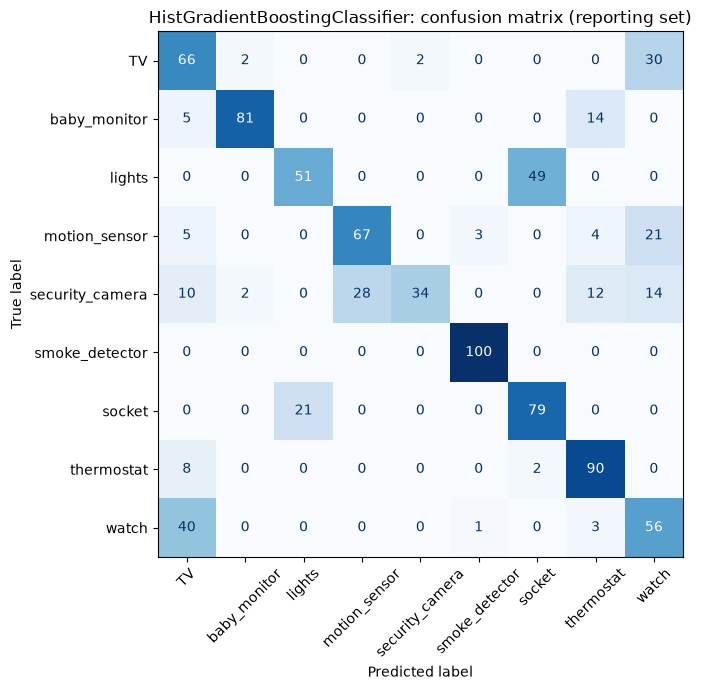

In [13]:
# GridSearchCV refits the best model on the full training set (refit=True by default).
hgb_accuracy, hgb_cm = evaluate_model(hgb_search.best_estimator_, X_report, y_report)

print(f"Reporting accuracy (HistGradientBoosting): {hgb_accuracy:.4f}")
print(f"Total hyperparameter search time: {hgb_search_minutes:.2f} minutes")
plot_confusion_matrix(hgb_cm, class_names, "HistGradientBoostingClassifier: confusion matrix (reporting set)")

In [14]:
per_class_recall(hgb_cm, class_names).to_frame()

,recall
security_camera,0.34
lights,0.51
watch,0.56
TV,0.66
motion_sensor,0.67
socket,0.79
baby_monitor,0.81
thermostat,0.90
smoke_detector,1.00


### 4. Reflection

**Computation time.** On our computer, the `HistGradientBoostingClassifier` search took about 0.49 minutes, and the `GradientBoostingClassifier` search took about 0.9 minutes. So the histogram method was 1.8x faster (45%). This gain is much smaller than the speed-ups that the documentation describes. The cause is the size of the dataset. With only 720 training samples per fold, sorting and testing every threshold is already cheap, so binning removes little work. The histogram method also has a fixed cost for binning and for thread management. With `n_jobs=-1`, the grid search and the OpenMP threads inside each model compete for the same CPU cores. With tens of thousands of samples, we expect a much larger difference.

**Predictive performance.** The two methods give almost the same results. The best CV accuracy is about 0.88 for the histogram method and 0.89 for the exact method. The reporting accuracy is about 0.69 for both. The small differences are within the variation between folds (see `std_test_score`), so neither method is clearly better here. Per class, the histogram model classifies `smoke_detector` and `thermostat` very well, while `security_camera`, `lights` and `watch` have the lowest recall on the reporting set. The two methods also select different hyperparameters. The selected hyperparameters (learning_rate=0.01, max_depth=8) should not be over-interpreted: three combinations tie at 0.878 CV accuracy, including a shallow tree with a high learning rate (max_depth=3, learning_rate=0.3), so the histogram method is not sensitive to these settings on this dataset.

**Gap between CV and reporting accuracy.** Both models lose almost 20 percentage points from CV to the reporting set. This shows that the reporting data does not come from exactly the same distribution as the training data (for example, different capture sessions). This gap is a property of the data, not of the boosting method.

**Trade-offs.**
- *For the histogram method:* faster training that scales well to large datasets, native support for missing values and categorical features, and built-in early stopping (not active here, since early_stopping='auto' only turns on above 10,000 samples).
- *Against the histogram method:* split thresholds are approximate (bin edges only), and the method has more hyperparameters that interact (`max_leaf_nodes`, `max_depth`, `max_bins`, `l2_regularization`). On a small dataset like this one, the speed gain is small, so the exact `GradientBoostingClassifier` is also an acceptable choice.
- *Conclusion:* for this lab, both methods give the same predictive performance. For a real network with many more traffic captures, the histogram method is the better choice because of its speed.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


### 4.1 - Preprocessing Reflection

Prior to building a neural network, it is important to standardize the data. This is done in order to maintain a similar scale across every feature to improve the performance of the model by preventing certain features from weighing more due to their larger values. This is done in the form of a pipeline so that there is no leakage across the CV folds.   
  
We did not need any other preprocessing steps since the features are already numeric and there are no missing values.

In [20]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        max_iter = 300,
        early_stopping=True,
        random_state=RANDOM_STATE
    )),
])

### 4.2 - Model Optimization and Training

In [21]:
mlp_param_grid = {
    "mlp__hidden_layer_sizes": [
        (32,), (64,), (128,),
        (32, 32), (64, 64), (128, 128),
        (32, 32, 32), (64, 64, 64), (128, 128, 128),
    ],
}

mlp_search, mlp_search_minutes = run_grid_search(
    mlp_pipeline, mlp_param_grid, cv, X_train, y_train,
)

print(f"Total hyperparameter search time: {mlp_search_minutes:.2f} minutes")
print("Best parameters:", mlp_search.best_params_)
print(f"Best mean CV accuracy: {mlp_search.best_score_:.4f}")
print("Epochs used:", mlp_search.best_estimator_.named_steps["mlp"].n_iter_)

summarize_cv_results(mlp_search)

Total hyperparameter search time: 0.15 minutes
Best parameters: {'mlp__hidden_layer_sizes': (64, 64, 64)}
Best mean CV accuracy: 0.8433
Epochs used: 36


,param_mlp__hidden_layer_sizes,mean_test_score,std_test_score,mean_fit_time
0,"(64, 64, 64)",0.843333,0.022608,0.590912
1,"(128, 128, 128)",0.843333,0.022055,0.714658
2,"(128, 128)",0.842222,0.030348,0.860789
3,"(32, 32)",0.838889,0.028328,0.589600
4,"(128,)",0.830000,0.023465,0.938354
5,"(32, 32, 32)",0.830000,0.014316,0.523578
6,"(64, 64)",0.826667,0.019052,0.447684
7,"(64,)",0.824444,0.015154,0.750282
8,"(32,)",0.814444,0.052068,0.668962


### 4.3 - Evaluate Performance

Reporting accuracy (MLP): 0.180 | Tuning time: 0.15 min
                 precision    recall  f1-score   support

             TV      0.286     0.100     0.148       100
   baby_monitor      0.045     0.120     0.065       100
         lights      0.000     0.000     0.000       100
  motion_sensor      0.059     0.020     0.030       100
security_camera      0.079     0.160     0.106       100
 smoke_detector      0.893     0.500     0.641       100
         socket      0.455     0.700     0.551       100
     thermostat      0.018     0.010     0.013       100
          watch      0.011     0.010     0.010       100

       accuracy                          0.180       900
      macro avg      0.205     0.180     0.174       900
   weighted avg      0.205     0.180     0.174       900



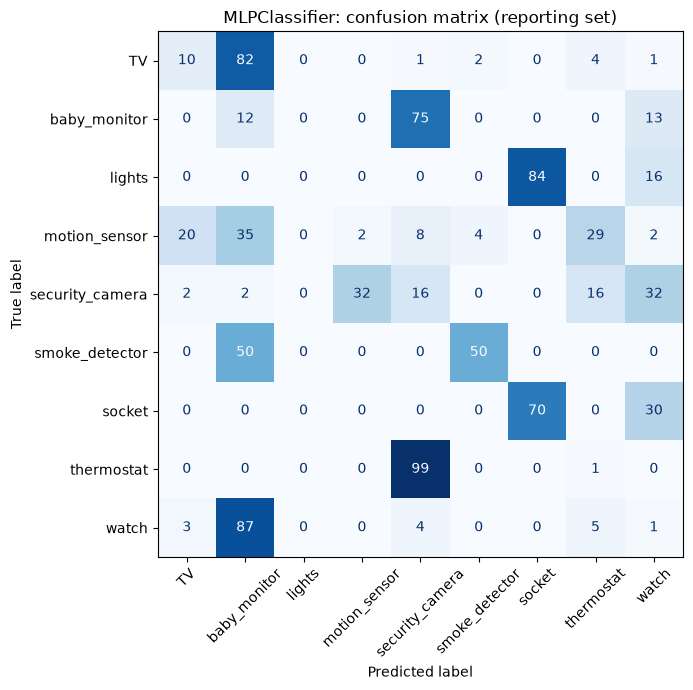

,CV accuracy,Reporting accuracy,Tuning time (min)
Gradient Boosting,0.890000,0.687778,1.126156
Random Forest,0.884444,0.584444,0.042590
HistGradientBoosting,0.877778,0.693333,1.432700
MLP,0.843333,0.180000,0.151948


In [22]:
mlp_accuracy, mlp_cm = evaluate_model(mlp_search.best_estimator_, X_report, y_report)
print(f"Reporting accuracy (MLP): {mlp_accuracy:.3f} | Tuning time: {mlp_search_minutes:.2f} min")
print(classification_report(y_report, mlp_search.best_estimator_.predict(X_report),
                            target_names=class_names, digits=3, zero_division=0))
plot_confusion_matrix(mlp_cm, class_names, "MLPClassifier: confusion matrix (reporting set)")

comparison = pd.DataFrame({
    "CV accuracy": [gb_search.best_score_, rf_search.best_score_, hgb_search.best_score_, mlp_search.best_score_],
    "Reporting accuracy": [summary.loc["Gradient Boosting", "Reporting accuracy"],
                           summary.loc["Random Forest", "Reporting accuracy"],
                           hgb_accuracy, mlp_accuracy],
    "Tuning time (min)": [fit_times["Gradient Boosting"], fit_times["Random Forest"],
                          hgb_search_minutes, mlp_search_minutes],
}, index=["Gradient Boosting", "Random Forest", "HistGradientBoosting", "MLP"])
comparison

The neural network had a slightly lower CV accuracy than the ensemble models, but with a reporting accuracy that was far lower. This value was close to chance, since the data has so many features that are constant in the training set and not the reporting. The StandardScaler is not able to scale them since they are constant in the training, so the extreme values are able to get to the network and dominate the weighted sums. This does not happen with the tree-based models, because a split only compares a feature to a threshold and those that are constant aren't used for a split. The neural network is more complex and needs scaling and early stopping, while the ensemble models did not need any preprocessing. It is also harder to interpret, since the effects of each feature are spread across many weights and hidden units, while the tree-based models give the feature importances directly. The ensemble models are the better choice for this dataset, as we can see with both the CV and reporting accuracies.

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our group's main challenge/inefficiency this week was ensuring that those who were able to complete their tasks first were doing the earlier steps. While we feel that we worked efficiently on this lab and used proper time management, we did have to communicate to make sure that necessary steps for 3 and 4 were being completed so that we could then work on the remainder of the lab. We managed the issue pretty well, communicating with one another about when we would finish our parts, allowing each of us enough time to then analyze the parts before ours and continue to the next step. 